In [12]:
# IMPORTING IMPORTANT LIBRARIES
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np 
import math
import keras
#import keras_hub
import tensorflow as tf
#from sklearn.preprocessing import MinMaxScaler
from sklearn.metrics import mean_squared_error
from keras.models import Sequential
from keras.layers import Dense, Activation
#from keras.layers import LSTM
from keras.layers import MultiHeadAttention, Input, Dropout, LayerNormalization

import preprocessor_transformer
import transformer_seq2seq

In [13]:
# FOR REPRODUCIBILITY
np.random.seed(7)

# IMPORTING DATASET 
dataset = pd.read_csv('Intel History Stock Price.csv', usecols=[1,2,3,4])
#dataset = dataset.reindex(index = dataset.index[::-1])

# CREATING OWN INDEX FOR FLEXIBILITY
obs = np.arange(1, len(dataset) + 1, 1)

# TAKING DIFFERENT INDICATORS FOR PREDICTION
OHLC_avg = dataset.mean(axis = 1)
#HLC_avg = dataset[['High', 'Low', 'Close']].mean(axis = 1)
#close_val = dataset[['Close']]

# PREPARATION OF TIME SERIES DATASE
OHLC_avg = np.reshape(OHLC_avg, (len(OHLC_avg),1)) 



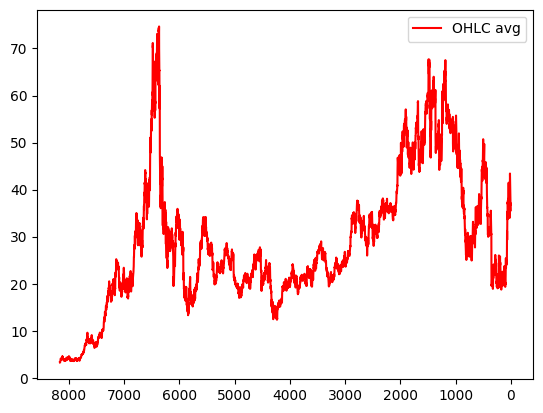

In [14]:
# PLOTTING ALL INDICATORS IN ONE PLOT
plt.plot(obs, OHLC_avg, 'r', label = 'OHLC avg')
ax = plt.gca() # Get current axes
ax.invert_xaxis()
plt.legend(loc = 'upper right')
plt.show()


In [15]:
# NORMALIZING THE DATASET
#scaler = MinMaxScaler(feature_range=(0, 1))
#OHLC_avg_scale = scaler.fit_transform(OHLC_avg)
#plt.plot(obs, OHLC_avg_scale, 'r', label = 'OHLC avg scaled')
#plt.legend(loc = 'upper right')
#plt.show()

# TRAIN-TEST SPLIT
train_OHLC = int(len(OHLC_avg) * 0.9)
test_OHLC = len(OHLC_avg) - train_OHLC
train_OHLC, test_OHLC = OHLC_avg[0:train_OHLC,:], OHLC_avg[train_OHLC:len(OHLC_avg),:]

# TIME-SERIES DATASET (FOR TIME T, VALUES FOR TIME T+1)
step_size = 90
pred_size = 7
trainX, trainY = preprocessor_transformer.new_dataset(train_OHLC, step_size, pred_size)
testX, testY = preprocessor_transformer.new_dataset(test_OHLC, step_size, pred_size)

# RESHAPING TRAIN AND TEST DATA
trainX = np.reshape(trainX, (trainX.shape[0], trainX.shape[1], 1))
testX = np.reshape(testX, (testX.shape[0], testX.shape[1], ))
trainY = np.reshape(trainY, (trainY.shape[0], trainY.shape[1], 1))
testY = np.reshape(testY, (testY.shape[0], testY.shape[1], 1))

print(trainX.shape, trainY.shape, testX.shape, testY.shape)
start = 10000.0
trainY_shift = np.concatenate([np.full((trainY.shape[0], 1, 1), start ,dtype=float) , trainY[:,:-1,]], axis=1)
print(trainY_shift[0:3,:,])


(7247, 90, 1) (7247, 7, 1) (720, 90) (720, 7, 1)
[[[10000.    ]
  [   23.9425]
  [   24.8325]
  [   22.9875]
  [   21.875 ]
  [   21.4075]
  [   20.785 ]]

 [[10000.    ]
  [   24.8325]
  [   22.9875]
  [   21.875 ]
  [   21.4075]
  [   20.785 ]
  [   19.895 ]]

 [[10000.    ]
  [   22.9875]
  [   21.875 ]
  [   21.4075]
  [   20.785 ]
  [   19.895 ]
  [   19.9525]]]


In [27]:
encoder_input = Input((step_size, 1), dtype="float32", name="encoder_input")
decoder_input = Input((pred_size, 1), dtype="float32", name="decoder_input")

transformer_model = transformer_seq2seq.Transformer(num_layers = 3, 
                                            embedding_dim = 2, 
                                            num_heads = 8, 
                                            fully_connected_dim = 16, 
                                            max_positional_encoding_input = step_size,
                                            max_positional_encoding_target = pred_size)

logits, _ = transformer_model(encoder_input, decoder_input)

model = tf.keras.Model( inputs=[encoder_input, decoder_input], outputs=[logits])

optimizer = tf.keras.optimizers.Adam(learning_rate=1e-4)
model.compile(optimizer=optimizer, loss='mean_squared_error', metrics=['accuracy']) 
model.fit(x=(trainX, trainY_shift), y=trainY, batch_size=8, epochs=25)
model.summary()

Epoch 1/25
906/906 ━━━━━━━━━━━━━━━━━━━━ 50s 36ms/step - accuracy: 0.0000e+00 - loss: 984.4324
Epoch 2/25
906/906 ━━━━━━━━━━━━━━━━━━━━ 33s 36ms/step - accuracy: 0.0000e+00 - loss: 818.1942
Epoch 3/25
906/906 ━━━━━━━━━━━━━━━━━━━━ 33s 36ms/step - accuracy: 0.0000e+00 - loss: 605.9608
Epoch 4/25
906/906 ━━━━━━━━━━━━━━━━━━━━ 34s 38ms/step - accuracy: 0.0000e+00 - loss: 400.2456
Epoch 5/25
906/906 ━━━━━━━━━━━━━━━━━━━━ 33s 37ms/step - accuracy: 0.0000e+00 - loss: 257.2871
Epoch 6/25
906/906 ━━━━━━━━━━━━━━━━━━━━ 41s 36ms/step - accuracy: 0.0000e+00 - loss: 198.2900
Epoch 7/25
906/906 ━━━━━━━━━━━━━━━━━━━━ 33s 37ms/step - accuracy: 0.0000e+00 - loss: 186.4659
Epoch 8/25
906/906 ━━━━━━━━━━━━━━━━━━━━ 33s 37ms/step - accuracy: 0.0000e+00 - loss: 184.4973
Epoch 9/25
906/906 ━━━━━━━━━━━━━━━━━━━━ 33s 36ms/step - accuracy: 0.0000e+00 - loss: 180.8612
Epoch 10/25
906/906 ━━━━━━━━━━━━━━━━━━━━ 33s 36ms/step - accuracy: 0.0000e+00 - loss: 178.5047
Epoch 11/25
906/906 ━━━━━━━━━━━━━━━━━━━━ 33s 36ms/step - ac

Model: "functional_77"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ encoder_input       │ (None, 90, 1)     │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ decoder_input       │ (None, 7, 1)      │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ transformer_11      │ [(None, 1),       │      2,162 │ encoder_input[0]… │
│ (Transformer)       │ (None, 8, 7, 7),  │            │ decoder_input[0]… │
│                     │ (None, 8, 7, 90), │            │                   │
│                     │ (None, 8, 7, 7),  │            │                   │
│                     │ (None, 8, 7, 90), │            │                   │
│                     │ (None, 8, 7, 7),  │            │                   │
│                     │ (None, 8, 7, 90)] │            │                   │
└─────────────────────┴───────────────────┴────────────┴───────────────────┘

 Total params: 6,488 (25.35 KB)

 Trainable params: 2,162 (8.45 KB)

 Non-trainable params: 0 (0.00 B)

 Optimizer params: 4,326 (16.90 KB)

In [28]:
# PREDICT FUTURE VALUES
last_vals = OHLC_avg[0:step_size]
last_vals = np.reshape(last_vals, (1,step_size,1))
print("Last Day Values", last_vals)

output_array = np.zeros((1,pred_size,1),dtype=float)
output_array[0,0,0] = start
predictions = np.zeros((pred_size,1), dtype=float)

for i in range(pred_size):
    output = output_array
    prediction = model.predict([last_vals, output])
    predictions[i] = prediction.squeeze()
    if i < pred_size - 1:
        output_array[0,i+1,0] = predictions[i]


print("Next Day Value:", predictions)

Last Day Values [[[35.615 ]
  [36.355 ]
  [37.1125]
  [36.83  ]
  [36.705 ]
  [36.8625]
  [37.4425]
  [37.91  ]
  [38.6775]
  [39.7125]
  [40.1925]
  [40.63  ]
  [41.015 ]
  [41.6375]
  [41.795 ]
  [43.42  ]
  [41.9175]
  [39.9625]
  [38.9725]
  [36.595 ]
  [35.5475]
  [35.4025]
  [33.97  ]
  [34.945 ]
  [34.86  ]
  [34.2275]
  [35.03  ]
  [35.3175]
  [36.485 ]
  [37.875 ]
  [37.935 ]
  [38.72  ]
  [37.6575]
  [38.055 ]
  [37.9   ]
  [37.5125]
  [39.8125]
  [40.3225]
  [40.6675]
  [41.475 ]
  [40.785 ]
  [39.2075]
  [39.3125]
  [37.3975]
  [37.1825]
  [38.07  ]
  [37.9375]
  [36.9575]
  [37.105 ]
  [36.67  ]
  [35.7175]
  [36.8625]
  [37.695 ]
  [37.5725]
  [36.92  ]
  [37.0525]
  [37.2225]
  [37.3275]
  [36.5175]
  [34.7575]
  [33.685 ]
  [34.445 ]
  [35.3275]
  [32.765 ]
  [30.3825]
  [29.3375]
  [29.315 ]
  [29.98  ]
  [31.2225]
  [24.9225]
  [25.03  ]
  [24.695 ]
  [24.3425]
  [24.7175]
  [24.585 ]
  [24.5125]
  [24.455 ]
  [24.4925]
  [24.2125]
  [23.975 ]
  [24.0025]
  [24.59  ]


/tmp/ipykernel_112552/584266276.py:15: DeprecationWarning: Conversion of an array with ndim > 0 to a scalar is deprecated, and will error in future. Ensure you extract a single element from your array before performing this operation. (Deprecated NumPy 1.25.)
  output_array[0,i+1,0] = predictions[i]


1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 40ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 54ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 28ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 31ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 30ms/step
Next Day Value: [[33.04605484]
 [32.0280838 ]
 [31.82993317]
 [31.82993317]
 [29.387043  ]
 [33.04605484]
 [30.0299511 ]]


In [ ]:
# PREDICTION
trainPredict = model.predict((trainX,trainX))
testPredict = model.predict((testX,testX))

# TRAINING RMSE
#trainScore = math.sqrt(mean_squared_error(trainY[0], trainPredict[:,0]))
#print('Train RMSE: %.2f' % (trainScore))

# TEST RMSE
#testScore = math.sqrt(mean_squared_error(testY[0], testPredict[:,0]))
#print('Test RMSE: %.2f' % (testScore))

# DE-NORMALIZING MAIN DATASET #
#OHLC_avg_normal = scaler.inverse_transform(OHLC_avg_scale)
# DE-NORMALIZING FOR PLOTTING

trainY = np.reshape(trainY, (trainY.shape[0], trainY.shape[1]))
testY = np.reshape(testY, (testY.shape[0], testY.shape[1]))

#trainPredict_normal = scaler.inverse_transform(trainPredict)
#trainY_normal = scaler.inverse_transform([trainY])
#testPredict_normal = scaler.inverse_transform(testPredict)
#testY_normal = scaler.inverse_transform([testY])


# CREATING SIMILAR DATASET TO PLOT TRAINING PREDICTIONS
trainPredictPlot = np.empty_like(OHLC_avg)
trainPredictPlot[:, :] = np.nan
trainPredictPlot[step_size:len(trainPredict)+step_size, :] = trainPredict

# CREATING SIMILAR DATASSET TO PLOT TEST PREDICTIONS
testPredictPlot = np.empty_like(OHLC_avg)
testPredictPlot[:, :] = np.nan
testPredictPlot[len(trainPredict)+(step_size*2)+1:len(OHLC_avg)-1, :] = testPredict

# PLOT OF MAIN OHLC VALUES, TRAIN PREDICTIONS AND TEST PREDICTIONS
plt.plot(OHLC_avg, 'g', label = 'original dataset')
plt.plot(trainPredictPlot, 'r', label = 'training set')
plt.plot(testPredictPlot, 'b', label = 'predicted stock price/test set')
plt.legend(loc = 'upper right')
plt.xlabel('Time in Days')
plt.ylabel('OHLC Value of Stocks')
plt.show()
